In [ ]:
import os
from zipfile import ZipFile
# Konfigurasi direktori untuk kaggle
os.environ['KAGGLE_CONFIG_DIR'] = "/content/.kaggle"

In [ ]:
# Periksa dan buat direktori dataset jika belum ada
dataset_dir = "/content/dataset"
os.makedirs(dataset_dir, exist_ok=True)

In [ ]:
# Pindah ke direktori dataset
os.chdir(dataset_dir)

In [ ]:
!kaggle datasets download -d tawsifurrahman/covid19-radiography-database

Dataset URL: https://www.kaggle.com/datasets/tawsifurrahman/covid19-radiography-database
License(s): copyright-authors
 98% 763M/778M [00:05<00:00, 146MB/s]
100% 778M/778M [00:05<00:00, 150MB/s]


In [ ]:
with ZipFile('covid19-radiography-database.zip', 'r') as zip_ref:
    zip_ref.extractall(dataset_dir)

In [ ]:
!pip install tensorflow

In [ ]:
!pip install imbalanced-learn

#Pre-Processing

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
from imblearn.over_sampling import RandomOverSampler
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.applications import VGG16, VGG19, ResNet50, InceptionV3, InceptionResNetV2
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Conv2D, MaxPooling2D, Flatten, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam
import time
import random

In [ ]:
# Helper function to visualize data count
def visualize_data_count(data_count, title='Number of Images per Category'):
    categories = list(data_count.keys())
    counts = list(data_count.values())

    # Print number of images per category
    for category, count in zip(categories, counts):
        print(f'{category}: {count} images')

    plt.figure(figsize=(10, 5))
    plt.bar(categories, counts, color=['blue', 'green'])
    plt.xlabel('Categories')
    plt.ylabel('Number of Images')
    plt.title(title)
    plt.show()

In [ ]:
# Load dataset
# Data directory and categories
data_dir = '/content/dataset/COVID-19_Radiography_Dataset'
categories = ['COVID/images', 'Normal/images']

# Load data
data = []
labels = []

img_size = 150

for category in categories:
    path = os.path.join(data_dir, category)
    class_num = categories.index(category)
    for img in os.listdir(path):
        try:
            img_array = tf.keras.preprocessing.image.load_img(os.path.join(path, img), target_size=(img_size, img_size))
            img_array = tf.keras.preprocessing.image.img_to_array(img_array)
            data.append(img_array)
            labels.append(class_num)
        except Exception as e:
            pass

data = np.array(data)
labels = np.array(labels)

COVID/images: 3616 images
Normal/images: 10192 images


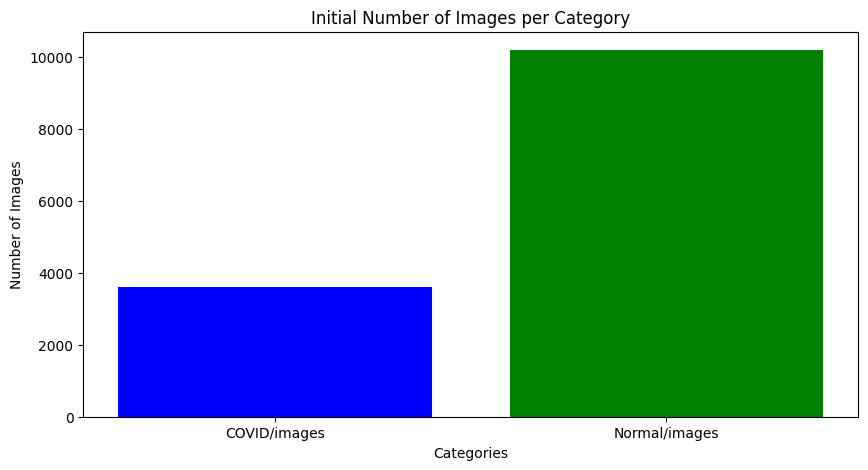

In [ ]:
# Check initial data count
unique, counts = np.unique(labels, return_counts=True)
data_count_initial = dict(zip([categories[i] for i in unique], counts))

# Visualize initial data count
visualize_data_count(data_count_initial, title='Initial Number of Images per Category')

###Oversampling

In [ ]:
# Resampling using RandomOverSampler
ros = RandomOverSampler(random_state=42)
data_reshaped = data.reshape(len(data), -1)  # Flatten the data for oversampling
X_resampled, y_resampled = ros.fit_resample(data_reshaped, labels)

In [ ]:
from sklearn.utils import shuffle
# Shuffle data after oversampling
X_resampled, y_resampled = shuffle(X_resampled, y_resampled, random_state=42)

In [ ]:
# Reshape the data back to original dimensions
X_resampled = X_resampled.reshape(-1, img_size, img_size, 3)
y_resampled = to_categorical(y_resampled, num_classes=len(categories))

In [ ]:
# Update data count after resampling
unique, counts = np.unique(np.argmax(y_resampled, axis=1), return_counts=True)
data_count_resampled = dict(zip([categories[i] for i in unique], counts))

COVID/images: 10192 images
Normal/images: 10192 images


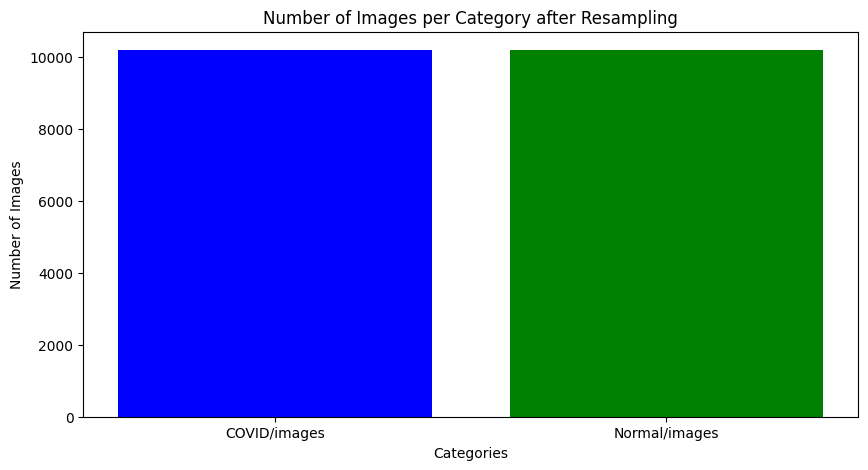

In [ ]:
# Update data count after resampling
unique, counts = np.unique(np.argmax(y_resampled, axis=1), return_counts=True)
data_count_resampled = dict(zip([categories[i] for i in unique], counts))
visualize_data_count(data_count_resampled, title='Number of Images per Category after Resampling')

###Data Split

In [ ]:
# Data split
X_train, X_temp, y_train, y_temp = train_test_split(X_resampled, y_resampled, test_size=0.3, random_state=42, stratify=y_resampled)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.67, random_state=42, stratify=y_temp)  # 0.67 * 0.3 ≈ 0.2

###Augmentasi Data

In [ ]:
# Data augmentation
datagen = ImageDataGenerator(
    rotation_range=20,             # Rotasi acak antara 0 hingga 20 derajat
    width_shift_range=0.1,         # Perpindahan horizontal acak
    height_shift_range=0.1,        # Perpindahan vertikal acak
    rescale=1/255,                 # Penskalaan nilai pixel menjadi [0, 1]
    shear_range=0.1,               # Shear transformations
    zoom_range=0.1,                # Zoom acak
    horizontal_flip=True,          # Membalik gambar secara horizontal
    fill_mode='nearest',           # Strategi pengisian piksel yang baru tercipta
)

In [ ]:
train_generator = datagen.flow(X_train, y_train, batch_size=32)
val_generator = datagen.flow(X_val, y_val, batch_size=32)
test_generator = datagen.flow(X_test, y_test, batch_size=32, shuffle=False)

In [ ]:
# Display augmented images
def display_augmented_images(datagen, images, labels, class_name):
    plt.figure(figsize=(12, 12))
    for i in range(9):
        augmented_images, _ = next(datagen.flow(images, labels, batch_size=1))
        plt.subplot(3, 3, i+1)
        plt.imshow(augmented_images[0])
        plt.axis('off')
    plt.suptitle(f'Augmented Images - {class_name}')
    plt.show()

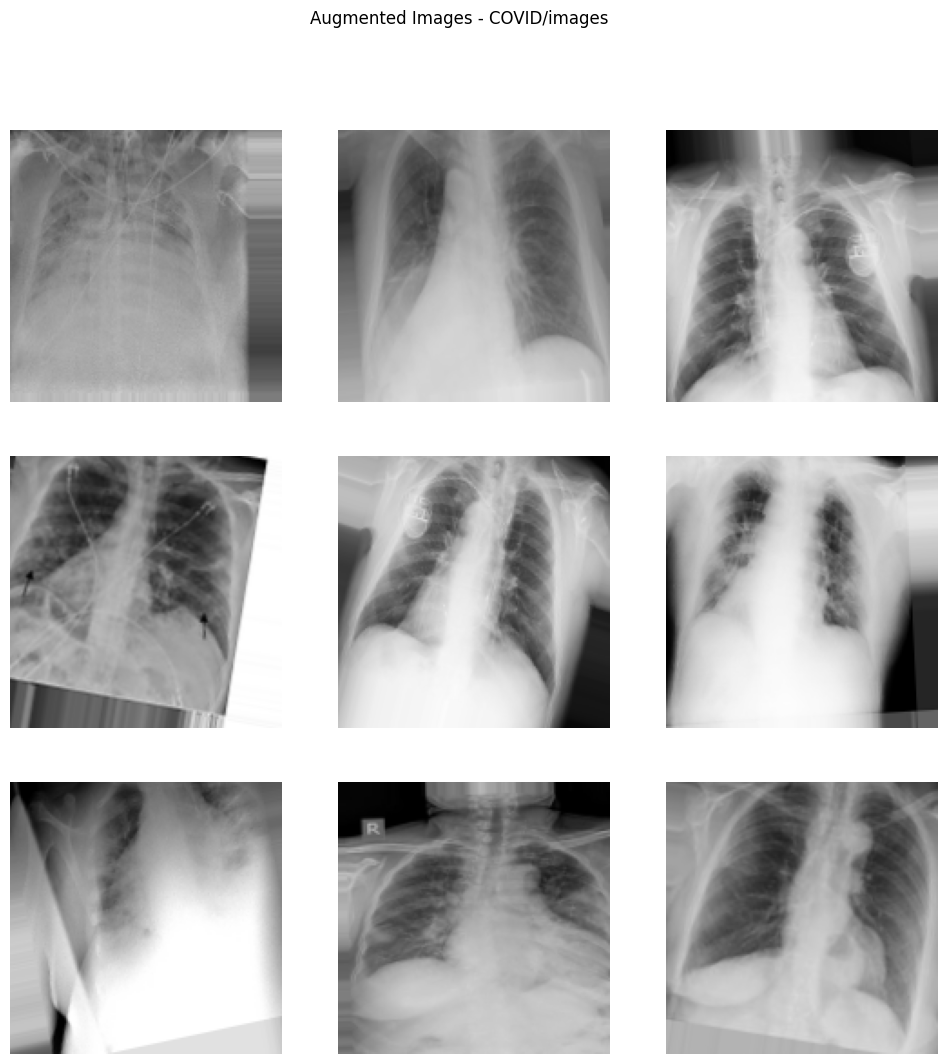

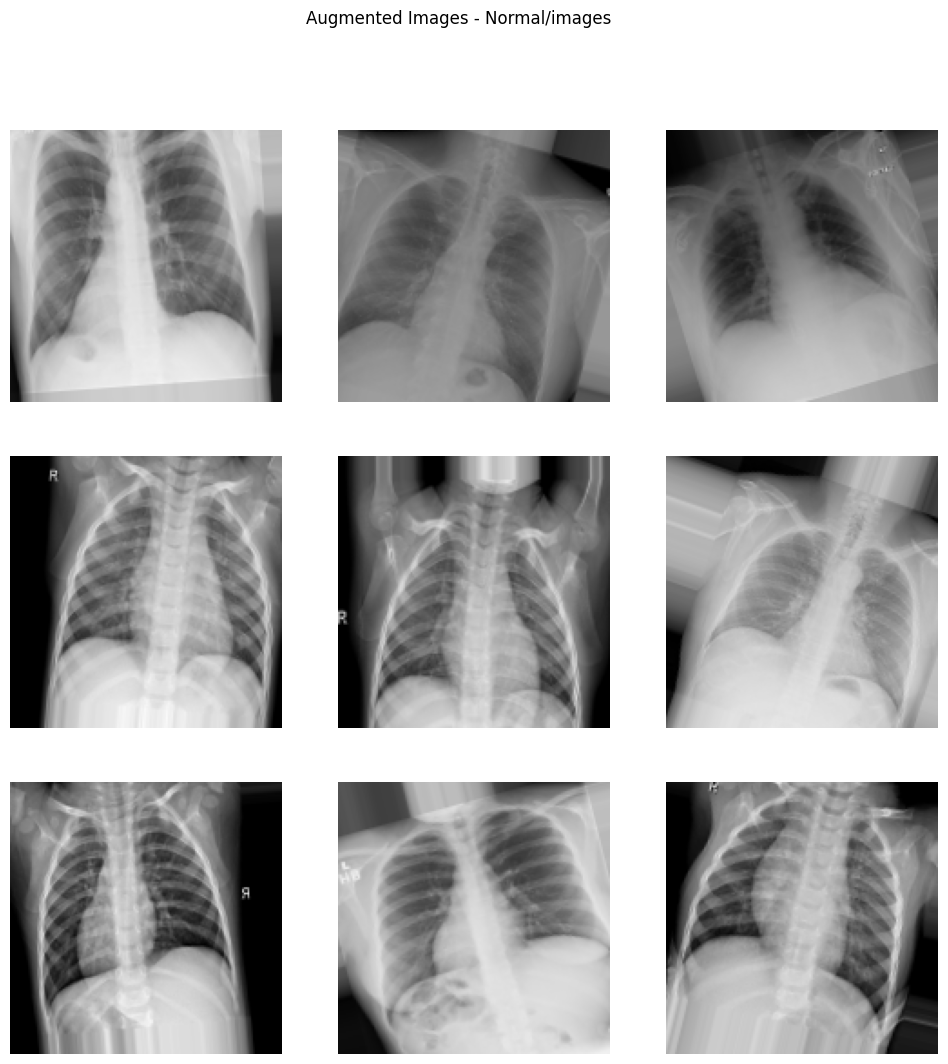

In [ ]:
# Display some augmented images for each class
for class_index, class_name in enumerate(categories):
    class_images = X_train[np.argmax(y_train, axis=1) == class_index]
    class_labels = y_train[np.argmax(y_train, axis=1) == class_index]
    display_augmented_images(datagen, class_images, class_labels, class_name)

###Plot Acc, Loss, Evaluate, Heatmap, Report Func

In [ ]:
# Model compilation and training function
def compile_and_train(model, train_generator, val_generator, epochs=100):
    model.compile(optimizer=Adam(learning_rate=0.0001), loss='categorical_crossentropy', metrics=['accuracy'])
    history = model.fit(train_generator, validation_data=val_generator, epochs=epochs)
    return history

In [ ]:
# Plot accuracy and loss
def plot_history(history, model_name):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs_range = range(len(acc))

    plt.figure(figsize=(12, 6))
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, label='Training Accuracy')
    plt.plot(epochs_range, val_acc, label='Validation Accuracy')
    plt.legend(loc='lower right')
    plt.title(f'{model_name} - Training and Validation Accuracy')

    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, label='Training Loss')
    plt.plot(epochs_range, val_loss, label='Validation Loss')
    plt.legend(loc='upper right')
    plt.title(f'{model_name} - Training and Validation Loss')
    plt.show()

In [ ]:
# Evaluation function
def evaluate_model(model, generator, true_labels):
    predictions = model.predict(generator, steps=len(generator))
    y_pred = np.argmax(predictions, axis=1)
    y_true = np.argmax(true_labels, axis=1)
    accuracy = np.mean(y_pred == y_true) * 100
    print(f'Test Accuracy: {accuracy:.2f}%')

    return y_true, y_pred

In [ ]:
# Create heatmap
def create_heatmap(y_true, y_pred_classes):
    correct_labels = ['COVID', 'Normal']
    cm = confusion_matrix(y_true, y_pred_classes)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=correct_labels, yticklabels=correct_labels)
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.title('Confusion Matrix')
    plt.show()

In [ ]:
# Report Classification
def report_classification(y_true, y_pred_classes):
    report = classification_report(y_true, y_pred_classes, target_names=categories)
    print(report)

In [ ]:
def load_and_preprocess_image(img_path, img_size):
    img = load_img(img_path, target_size=(img_size, img_size))
    img_array = img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)
    img_array = img_array / 255.0  # Normalisasi gambar
    return img_array

In [ ]:
def predict_and_display(model, img_path, img_size, class_names):
    img_array = load_and_preprocess_image(img_path, img_size)

    start_time = time.time()
    prediction = model.predict(img_array)
    elapsed_time = time.time() - start_time

    predicted_class = np.argmax(prediction, axis=1)[0]
    predicted_class_name = class_names[predicted_class]
    accuracy = np.max(prediction)

    plt.figure(figsize=(5, 5))
    plt.imshow(load_img(img_path))
    plt.title(f'Prediksi = {predicted_class_name}\nakurasi = {accuracy:.6f}\nLama Waktu = {elapsed_time:.3f} Detik')
    plt.axis('off')
    plt.show()

In [ ]:
def get_random_image_path(category_dir):
    category_path = os.path.join(data_dir, category_dir)
    random_image = random.choice(os.listdir(category_path))
    return os.path.join(category_path, random_image)

img_path_covid = get_random_image_path(categories[0])
img_path_normal = get_random_image_path(categories[1])

#CNN-Handcraft

In [ ]:
# Model Definitions
def create_handcraft_cnn(input_shape, num_classes):
    model = Sequential([
        Conv2D(32, (3, 3), activation='relu', input_shape=input_shape),
        MaxPooling2D((2, 2)),
        Conv2D(64, (3, 3), activation='relu'),
        MaxPooling2D((2, 2)),
        Flatten(),
        Dense(128, activation='relu'),
        Dropout(0.5),
        Dense(num_classes, activation='softmax')
    ])
    return model

###Model Training

Training CNN Handcraft...
Epoch 1/100
446/446 [==============================] - 84s 176ms/step - loss: 0.6361 - accuracy: 0.6684 - val_loss: 0.5909 - val_accuracy: 0.6928
Epoch 2/100
446/446 [==============================] - 78s 174ms/step - loss: 0.5192 - accuracy: 0.7464 - val_loss: 0.5099 - val_accuracy: 0.7537
Epoch 3/100
446/446 [==============================] - 76s 171ms/step - loss: 0.4737 - accuracy: 0.7754 - val_loss: 0.4964 - val_accuracy: 0.7676
Epoch 4/100
446/446 [==============================] - 78s 174ms/step - loss: 0.4390 - accuracy: 0.8029 - val_loss: 0.4192 - val_accuracy: 0.8057
Epoch 5/100
446/446 [==============================] - 77s 174ms/step - loss: 0.4130 - accuracy: 0.8138 - val_loss: 0.3878 - val_accuracy: 0.8246
Epoch 6/100
446/446 [==============================] - 77s 174ms/step - loss: 0.3981 - accuracy: 0.8230 - val_loss: 0.4379 - val_accuracy: 0.8082
Epoch 7/100
446/446 [==============================] - 77s 172ms/step - loss: 0.3993 - accuracy: 0

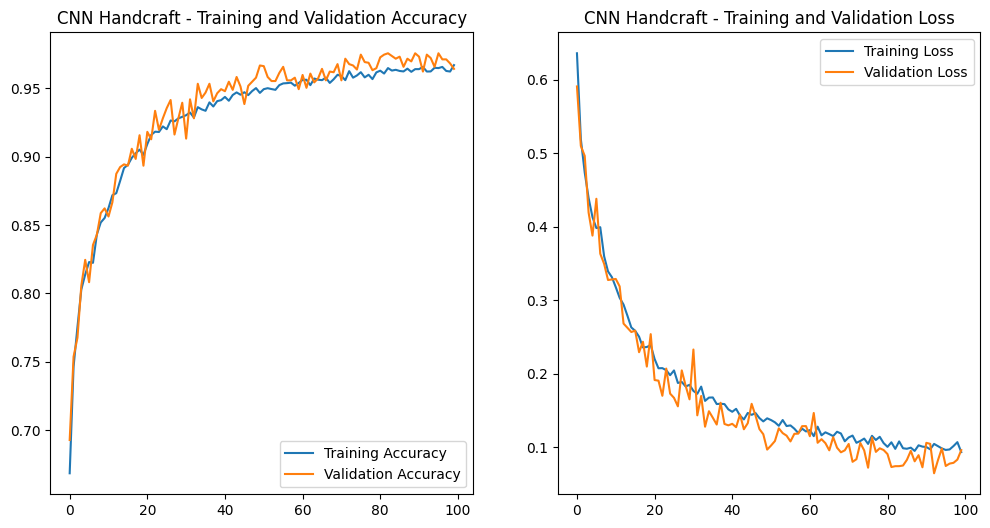

In [ ]:
# Training handcraftt CNN
print("Training CNN Handcraft...")
input_shape = (img_size, img_size, 3)
num_classes = len(categories)
model_Handcraft = create_handcraft_cnn(input_shape, num_classes)
history_Handcraft = compile_and_train(model_Handcraft, train_generator, val_generator, epochs=100)
plot_history(history_Handcraft, "CNN Handcraft")

###Evaluasi

Evaluating CNN handcraft on test data...
129/129 [==============================] - 18s 139ms/step
Test Accuracy: 96.66%


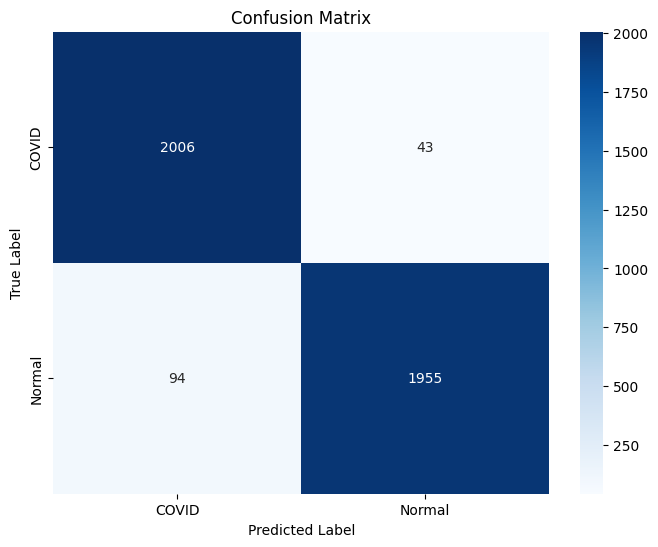

               precision    recall  f1-score   support

 COVID/images       0.96      0.98      0.97      2049
Normal/images       0.98      0.95      0.97      2049

     accuracy                           0.97      4098
    macro avg       0.97      0.97      0.97      4098
 weighted avg       0.97      0.97      0.97      4098



In [ ]:
# Evaluating handcraft CNN
print("Evaluating CNN handcraft on test data...")
y_true_handcraft, y_pred_handcraft = evaluate_model(model_Handcraft, test_generator, y_test)
create_heatmap(y_true_handcraft, y_pred_handcraft)
report_classification(y_true_handcraft, y_pred_handcraft)

###Test Prediksi model CNN-Handcraft

Prediksi untuk gambar COVID:
1/1 [==============================] - 0s 231ms/step


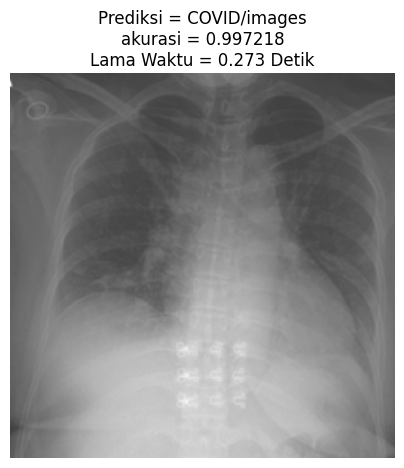

In [ ]:
print("Prediksi untuk gambar COVID:")
predict_and_display(model_Handcraft, img_path_covid, img_size, categories)

Prediksi untuk gambar Normal:
1/1 [==============================] - 0s 17ms/step


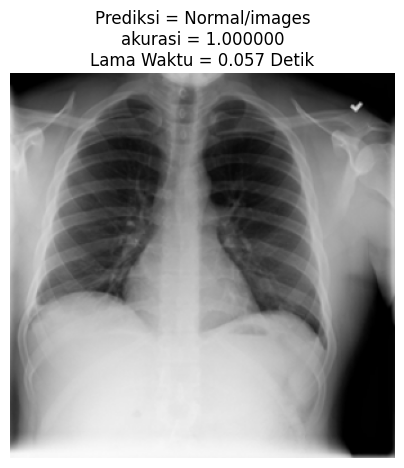

In [ ]:
print("Prediksi untuk gambar Normal:")
predict_and_display(model_Handcraft, img_path_normal, img_size, categories)

#VGG16

In [ ]:
from tensorflow.keras.applications import VGG16
from tensorflow.keras.regularizers import l2
# Model Definitions
def create_vgg16(input_shape, num_classes):
    base_model = VGG16(weights='imagenet', include_top=False, input_shape=input_shape)
    model = Sequential([
        base_model,
        Flatten(),
        Dense(256, activation='relu', kernel_regularizer=l2(0.001)),
        Dropout(0.5),
        Dense(num_classes, activation='softmax')
    ])
    return model

###Model Training

Training VGG16...
Epoch 1/100
446/446 [==============================] - 109s 235ms/step - loss: 0.6358 - accuracy: 0.7907 - val_loss: 0.3464 - val_accuracy: 0.9049
Epoch 2/100
446/446 [==============================] - 104s 234ms/step - loss: 0.2893 - accuracy: 0.9158 - val_loss: 0.2669 - val_accuracy: 0.9197
Epoch 3/100
446/446 [==============================] - 104s 234ms/step - loss: 0.1987 - accuracy: 0.9427 - val_loss: 0.1642 - val_accuracy: 0.9534
Epoch 4/100
446/446 [==============================] - 104s 232ms/step - loss: 0.1555 - accuracy: 0.9548 - val_loss: 0.1341 - val_accuracy: 0.9633
Epoch 5/100
446/446 [==============================] - 104s 233ms/step - loss: 0.1328 - accuracy: 0.9631 - val_loss: 0.1282 - val_accuracy: 0.9643
Epoch 6/100
446/446 [==============================] - 104s 233ms/step - loss: 0.1120 - accuracy: 0.9673 - val_loss: 0.1214 - val_accuracy: 0.9668
Epoch 7/100
446/446 [==============================] - 103s 232ms/step - loss: 0.1009 - accuracy: 0.

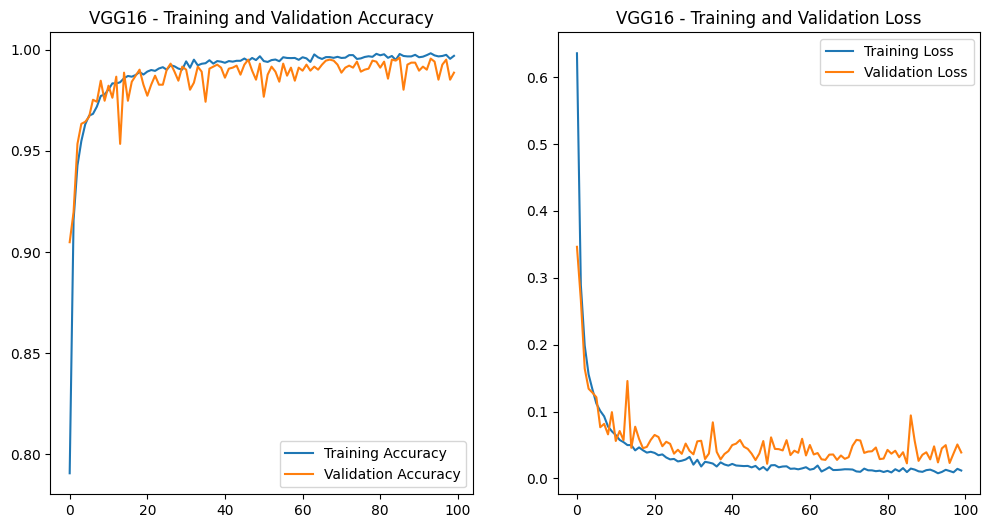

In [ ]:
# Training VGG16
print("Training VGG16...")
input_shape = (img_size, img_size, 3)
num_classes = len(categories)
model_vgg16 = create_vgg16(input_shape, num_classes)
history_vgg16 = compile_and_train(model_vgg16, train_generator, val_generator, epochs=100)
plot_history(history_vgg16, "VGG16")

###Evaluasi

Evaluating VGG16 on test data...
129/129 [==============================] - 19s 143ms/step
Test Accuracy: 99.07%


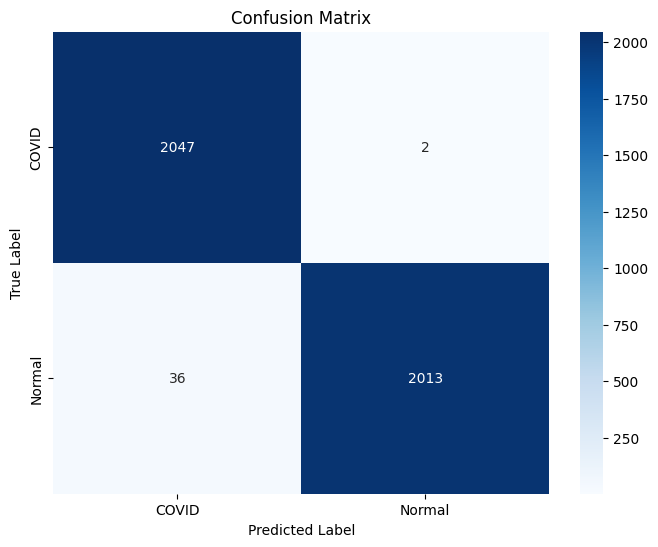

               precision    recall  f1-score   support

 COVID/images       0.98      1.00      0.99      2049
Normal/images       1.00      0.98      0.99      2049

     accuracy                           0.99      4098
    macro avg       0.99      0.99      0.99      4098
 weighted avg       0.99      0.99      0.99      4098



In [ ]:
# Evaluating VGG16
print("Evaluating VGG16 on test data...")
y_true_vgg16, y_pred_vgg16 = evaluate_model(model_vgg16, test_generator, y_test)
create_heatmap(y_true_vgg16, y_pred_vgg16)
report_classification(y_true_vgg16, y_pred_vgg16)

### Test Prediksi model VGG16

Prediksi untuk gambar COVID:
1/1 [==============================] - 1s 901ms/step


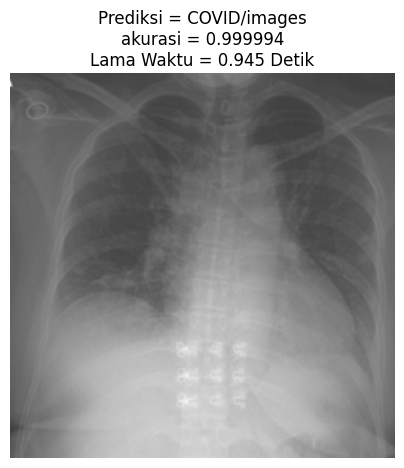

In [ ]:
print("Prediksi untuk gambar COVID:")
predict_and_display(model_vgg16, img_path_covid, img_size, categories)

Prediksi untuk gambar Normal:
1/1 [==============================] - 0s 18ms/step


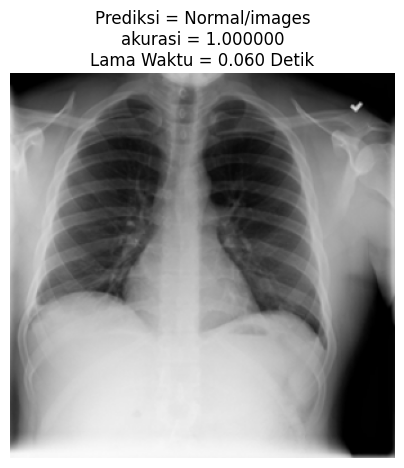

In [ ]:
print("Prediksi untuk gambar Normal:")
predict_and_display(model_vgg16, img_path_normal, img_size, categories)

#VGG19

In [ ]:
from tensorflow.keras.applications import VGG19

# Model Definitions
def create_vgg19(input_shape, num_classes):
    base_model = VGG19(weights='imagenet', include_top=False, input_shape=input_shape)
    model = Sequential([
        base_model,
        Flatten(),
        Dense(256, activation='relu', kernel_regularizer=l2(0.001)),
        BatchNormalization(),
        Dropout(0.5),
        Dense(num_classes, activation='softmax')
    ])
    return model

###Model Training

Training VGG19...
Epoch 1/100
446/446 [==============================] - 129s 278ms/step - loss: 0.7422 - accuracy: 0.7998 - val_loss: 2.5277 - val_accuracy: 0.5302
Epoch 2/100
446/446 [==============================] - 124s 277ms/step - loss: 0.4209 - accuracy: 0.9044 - val_loss: 0.4386 - val_accuracy: 0.8821
Epoch 3/100
446/446 [==============================] - 124s 277ms/step - loss: 0.3345 - accuracy: 0.9271 - val_loss: 0.4304 - val_accuracy: 0.8627
Epoch 4/100
446/446 [==============================] - 124s 277ms/step - loss: 0.2678 - accuracy: 0.9428 - val_loss: 0.3562 - val_accuracy: 0.9073
Epoch 5/100
446/446 [==============================] - 123s 277ms/step - loss: 0.2226 - accuracy: 0.9504 - val_loss: 0.7587 - val_accuracy: 0.7839
Epoch 6/100
446/446 [==============================] - 123s 276ms/step - loss: 0.2017 - accuracy: 0.9521 - val_loss: 0.8458 - val_accuracy: 0.7636
Epoch 7/100
446/446 [==============================] - 123s 277ms/step - loss: 0.1647 - accuracy: 0.

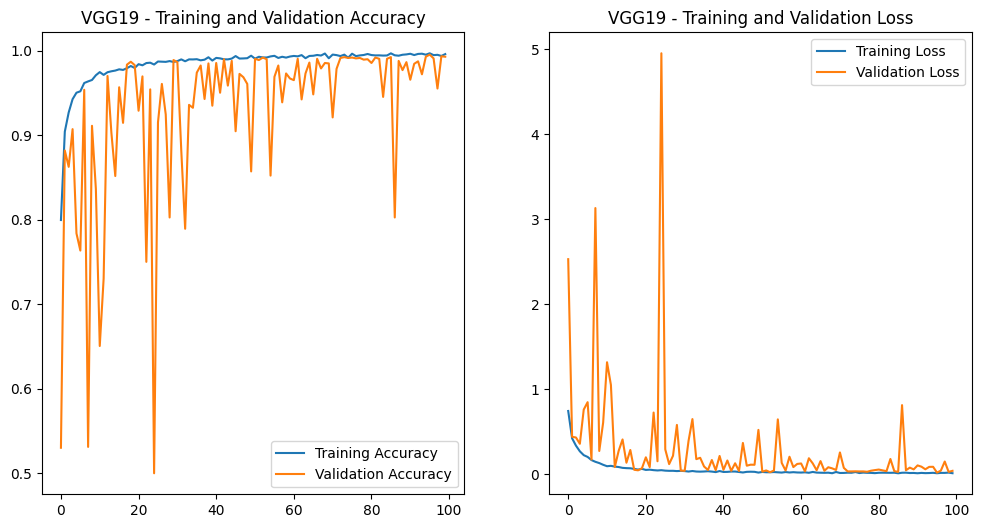

In [ ]:
# Training VGG19
print("Training VGG19...")
input_shape = (img_size, img_size, 3)
num_classes = len(categories)
model_vgg19 = create_vgg19(input_shape, num_classes)
history_vgg19 = compile_and_train(model_vgg19, train_generator, val_generator, epochs=100)
plot_history(history_vgg19, "VGG19")

###Evaluasi

Evaluating VGG19 on test data...
129/129 [==============================] - 18s 142ms/step
Test Accuracy: 99.59%


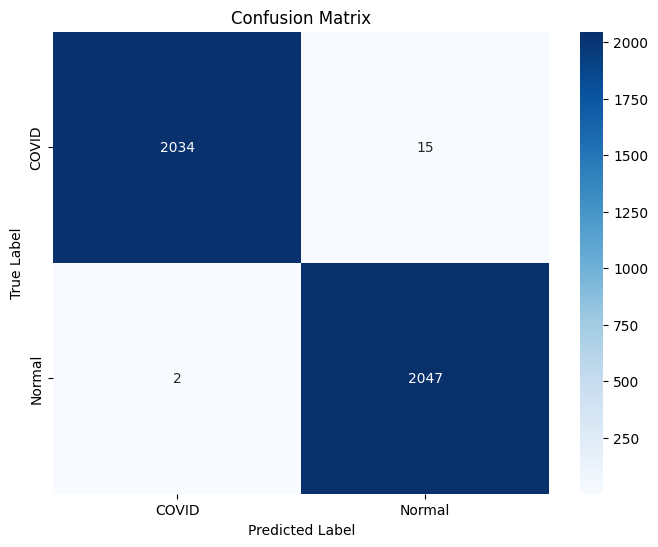

               precision    recall  f1-score   support

 COVID/images       1.00      0.99      1.00      2049
Normal/images       0.99      1.00      1.00      2049

     accuracy                           1.00      4098
    macro avg       1.00      1.00      1.00      4098
 weighted avg       1.00      1.00      1.00      4098



In [ ]:
# Evaluating VGG19
print("Evaluating VGG19 on test data...")
y_true_vgg19, y_pred_vgg19 = evaluate_model(model_vgg19, test_generator, y_test)
create_heatmap(y_true_vgg19, y_pred_vgg19)
report_classification(y_true_vgg19, y_pred_vgg19)

###Test Prediksi model VGG19

Prediksi untuk gambar COVID:
1/1 [==============================] - 0s 173ms/step


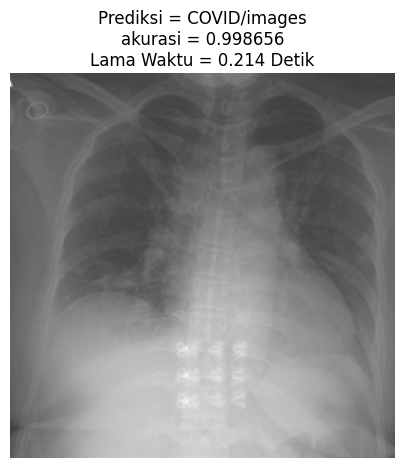

In [ ]:
print("Prediksi untuk gambar COVID:")
predict_and_display(model_vgg19, img_path_covid, img_size, categories)

Prediksi untuk gambar Normal:
1/1 [==============================] - 0s 18ms/step


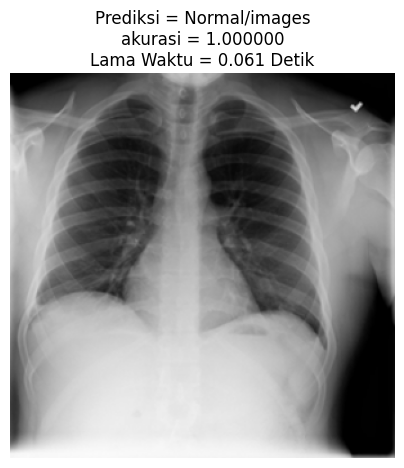

In [ ]:
print("Prediksi untuk gambar Normal:")
predict_and_display(model_vgg19, img_path_normal, img_size, categories)

#ResNet50

In [ ]:
from tensorflow.keras.applications import ResNet50

# Model Definitions
def create_resnet50(input_shape, num_classes):
    base_model = ResNet50(weights='imagenet', include_top=False, input_shape=input_shape)
    model = Sequential([
        base_model,
        Flatten(),
        Dense(256, activation='relu', kernel_regularizer=l2(0.001)),
        Dropout(0.5),
        Dense(num_classes, activation='softmax')
    ])
    return model

###Model Training

Training ResNet50...
Epoch 1/100
446/446 [==============================] - 124s 216ms/step - loss: 0.6880 - accuracy: 0.9169 - val_loss: 1.5852 - val_accuracy: 0.5020
Epoch 2/100
446/446 [==============================] - 95s 214ms/step - loss: 0.4657 - accuracy: 0.9660 - val_loss: 0.9519 - val_accuracy: 0.7121
Epoch 3/100
446/446 [==============================] - 95s 213ms/step - loss: 0.3839 - accuracy: 0.9764 - val_loss: 0.4835 - val_accuracy: 0.9281
Epoch 4/100
446/446 [==============================] - 95s 213ms/step - loss: 0.3242 - accuracy: 0.9820 - val_loss: 0.3415 - val_accuracy: 0.9658
Epoch 5/100
446/446 [==============================] - 95s 213ms/step - loss: 0.2708 - accuracy: 0.9850 - val_loss: 0.3707 - val_accuracy: 0.9390
Epoch 6/100
446/446 [==============================] - 95s 213ms/step - loss: 0.2449 - accuracy: 0.9814 - val_loss: 0.7985 - val_accuracy: 0.8206
Epoch 7/100
446/446 [==============================] - 95s 213ms/step - loss: 0.2143 - accuracy: 0.982

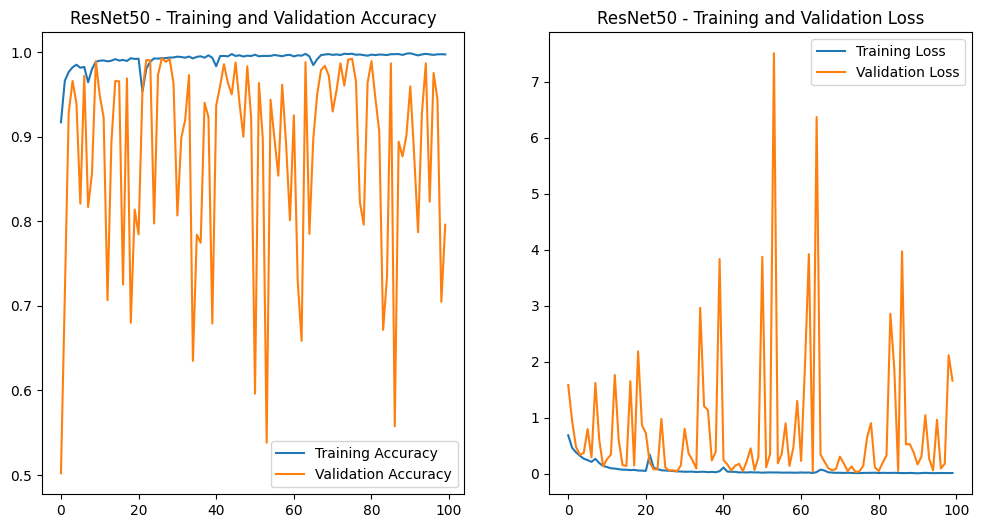

In [ ]:
# Training ResNet50
print("Training ResNet50...")
input_shape = (img_size, img_size, 3)
num_classes = len(categories)
model_resnet50 = create_resnet50(input_shape, num_classes)
history_resnet50 = compile_and_train(model_resnet50, train_generator, val_generator, epochs=100)
plot_history(history_resnet50, "ResNet50")

###Evaluasi

Evaluating ResNet50 on test data...
129/129 [==============================] - 20s 146ms/step
Test Accuracy: 77.75%


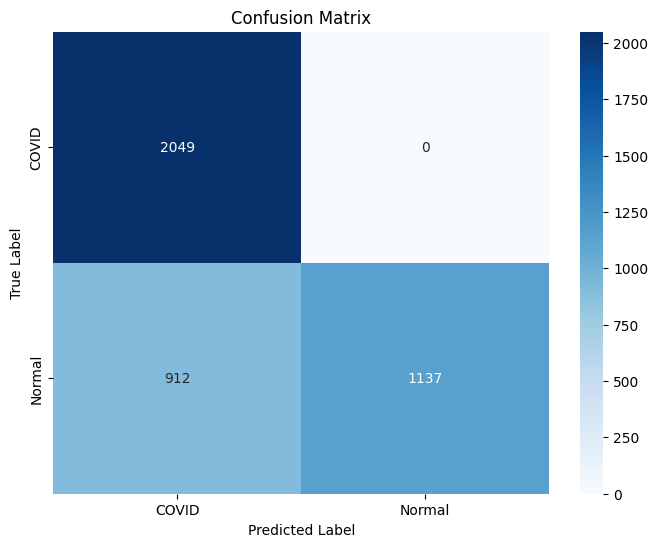

               precision    recall  f1-score   support

 COVID/images       0.69      1.00      0.82      2049
Normal/images       1.00      0.55      0.71      2049

     accuracy                           0.78      4098
    macro avg       0.85      0.78      0.77      4098
 weighted avg       0.85      0.78      0.77      4098



In [ ]:
# Evaluating ResNet50
print("Evaluating ResNet50 on test data...")
y_true_resnet50, y_pred_resnet50 = evaluate_model(model_resnet50, test_generator, y_test)
create_heatmap(y_true_resnet50, y_pred_resnet50)
report_classification(y_true_resnet50, y_pred_resnet50)

###Test Prediksi Model ResNet50

Prediksi untuk gambar COVID:
1/1 [==============================] - 2s 2s/step


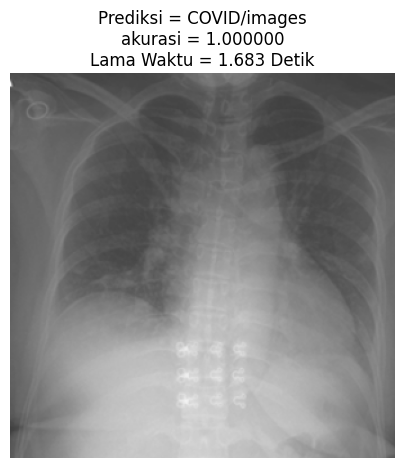

In [ ]:
print("Prediksi untuk gambar COVID:")
predict_and_display(model_resnet50, img_path_covid, img_size, categories)

Prediksi untuk gambar Normal:
1/1 [==============================] - 0s 25ms/step


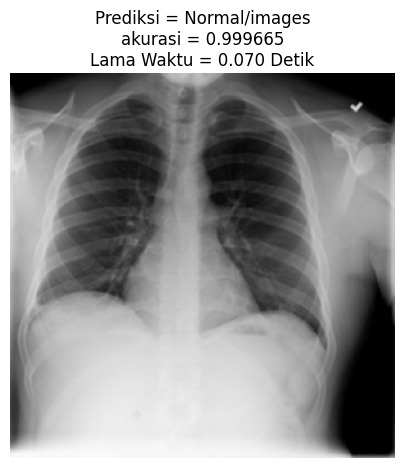

In [ ]:
print("Prediksi untuk gambar Normal:")
predict_and_display(model_resnet50, img_path_normal, img_size, categories)

#InceptionV3

In [ ]:
from tensorflow.keras.applications import InceptionV3

# Model Definitions
def create_inceptionv3(input_shape, num_classes):
    base_model = InceptionV3(weights='imagenet', include_top=False, input_shape=input_shape)
    model = Sequential([
        base_model,
        Flatten(),
        Dense(256, activation='relu', kernel_regularizer=l2(0.001)),
        Dropout(0.5),
        Dense(num_classes, activation='softmax')
    ])
    return model

###Model Training

Training InceptionV3...
Epoch 1/100
446/446 [==============================] - 105s 175ms/step - loss: 0.7154 - accuracy: 0.8902 - val_loss: 0.6368 - val_accuracy: 0.9039
Epoch 2/100
446/446 [==============================] - 77s 171ms/step - loss: 0.4655 - accuracy: 0.9586 - val_loss: 0.4462 - val_accuracy: 0.9604
Epoch 3/100
446/446 [==============================] - 76s 170ms/step - loss: 0.3533 - accuracy: 0.9725 - val_loss: 0.3315 - val_accuracy: 0.9628
Epoch 4/100
446/446 [==============================] - 76s 171ms/step - loss: 0.2706 - accuracy: 0.9786 - val_loss: 0.2261 - val_accuracy: 0.9846
Epoch 5/100
446/446 [==============================] - 76s 169ms/step - loss: 0.2147 - accuracy: 0.9809 - val_loss: 0.1873 - val_accuracy: 0.9866
Epoch 6/100
446/446 [==============================] - 76s 170ms/step - loss: 0.1663 - accuracy: 0.9825 - val_loss: 0.1493 - val_accuracy: 0.9856
Epoch 7/100
446/446 [==============================] - 76s 170ms/step - loss: 0.1294 - accuracy: 0.

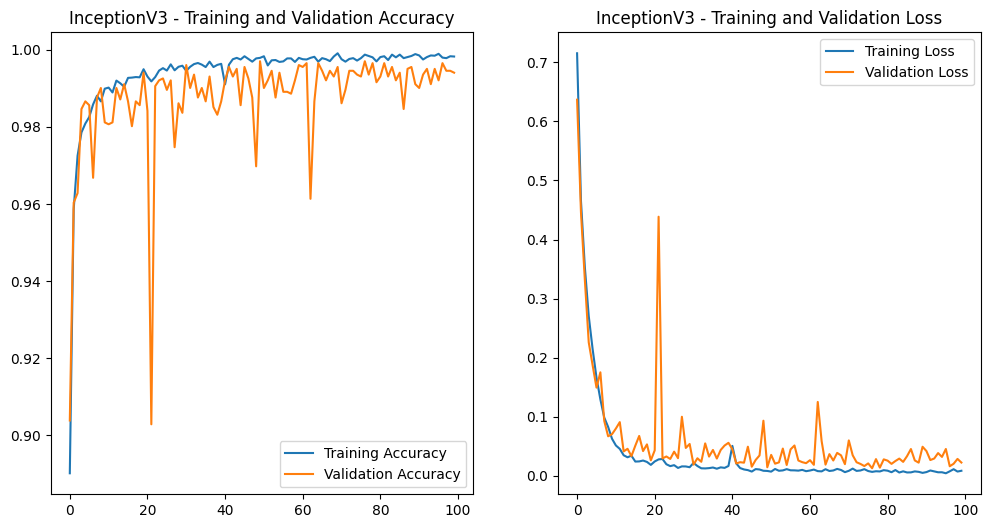

In [ ]:
# Training InceptionV3
print("Training InceptionV3...")
input_shape = (img_size, img_size, 3)
num_classes = len(categories)
model_inceptionv3 = create_inceptionv3(input_shape, num_classes)
history_inceptionv3 = compile_and_train(model_inceptionv3, train_generator, val_generator, epochs=100)
plot_history(history_inceptionv3, "InceptionV3")

###Evaluasi

Evaluating InceptionV3 on test data...
129/129 [==============================] - 20s 146ms/step
Test Accuracy: 99.54%


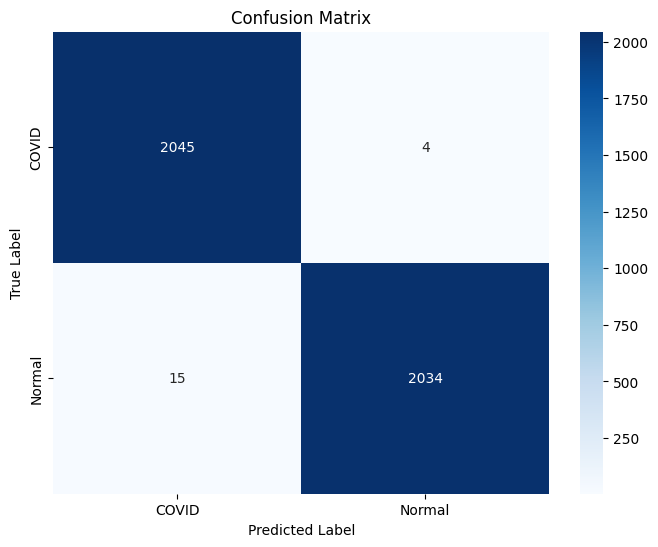

               precision    recall  f1-score   support

 COVID/images       0.99      1.00      1.00      2049
Normal/images       1.00      0.99      1.00      2049

     accuracy                           1.00      4098
    macro avg       1.00      1.00      1.00      4098
 weighted avg       1.00      1.00      1.00      4098



In [ ]:
# Evaluating InceptionV3
print("Evaluating InceptionV3 on test data...")
y_true_inceptionv3, y_pred_inceptionv3 = evaluate_model(model_inceptionv3, test_generator, y_test)
create_heatmap(y_true_inceptionv3, y_pred_inceptionv3)
report_classification(y_true_inceptionv3, y_pred_inceptionv3)

###Test Prediksi Model InceptionV3

Prediksi untuk gambar COVID:
1/1 [==============================] - 2s 2s/step


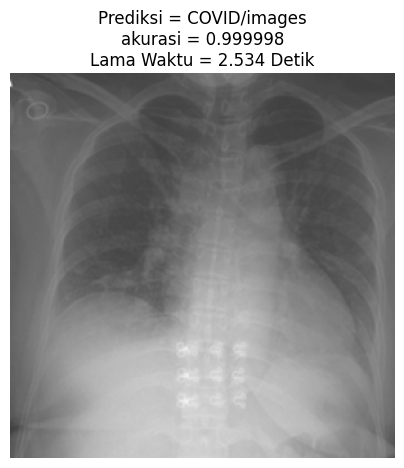

In [ ]:
print("Prediksi untuk gambar COVID:")
predict_and_display(model_inceptionv3, img_path_covid, img_size, categories)

Prediksi untuk gambar Normal:
1/1 [==============================] - 0s 28ms/step


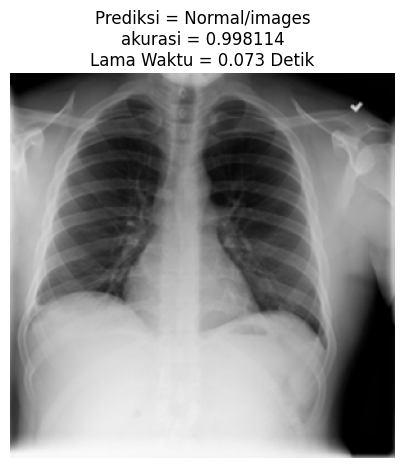

In [ ]:
print("Prediksi untuk gambar Normal:")
predict_and_display(model_inceptionv3, img_path_normal, img_size, categories)